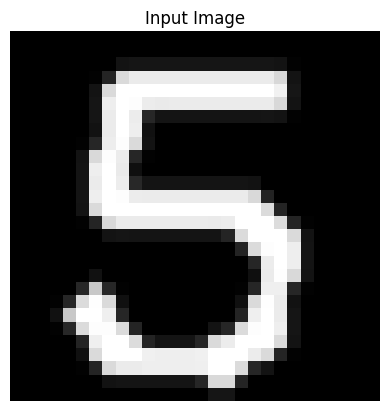

Image size: (28, 28)
Number of features: 784

BPNN training completed successfully.

Accuracy: 0.9805555555555555

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      0.97      0.95        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.94      0.91      0.93        35
           9       1.00      0.97      0.99        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



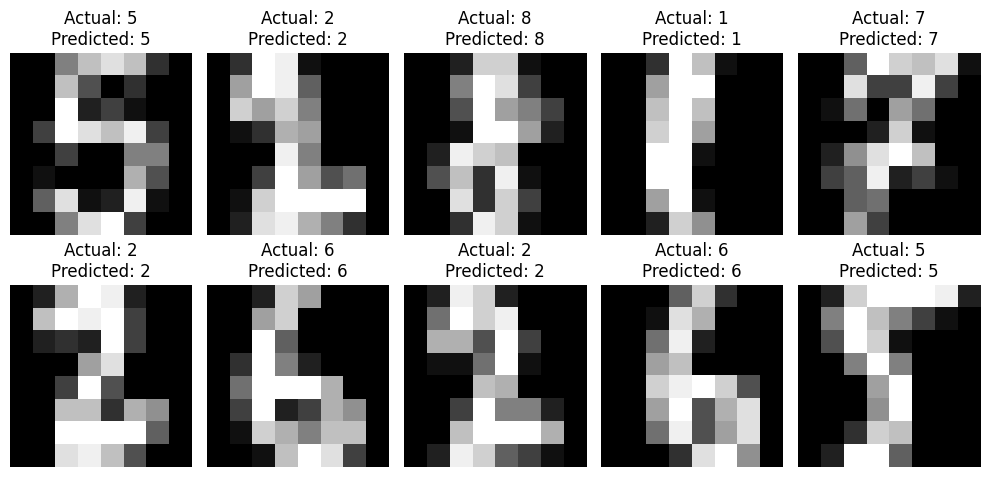


Predicted digit for input image: 7


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_digits

# Step 1: Load input image
image_path = "/content/Task 10 Input Image.jpg"

img = Image.open(image_path).convert("L")
img = img.resize((28, 28))

plt.imshow(img, cmap="gray")
plt.title("Input Image")
plt.axis("off")
plt.show()

# Step 2: Convert image into numerical data
image_array = np.array(img) / 255.0
image_features = image_array.reshape(1, -1)

print("Image size:", image_array.shape)
print("Number of features:", image_features.shape[1])

# Step 3: Create training data
digits = load_digits()
X = digits.data / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42, stratify=y
)

# Step 4: Create BPNN model
model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42
)

# Step 5: Train the model
model.fit(X_train, y_train)
print("\nBPNN training completed successfully.")

# Step 6: Test the model
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 7: Display predictions
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(8, 8), cmap="gray")
    plt.title(
        "Actual: " + str(y_test[i]) +
        "\nPredicted: " + str(y_pred[i])
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step 8: Predict supplied image
test_img = Image.open(image_path).convert("L")
test_img = test_img.resize((8, 8))

test_array = np.array(test_img)

# Match the dataset's white digit on dark background
test_array = 255 - test_array

test_array = test_array / 255.0
test_features = test_array.reshape(1, -1)

prediction = model.predict(test_features)

print("\nPredicted digit for input image:", prediction[0])